# EDA — UCF-Crime MINI

Exploratory data analysis of the dataset used in notebooks 01–03. Everything is read from the videos and the split files; no model is involved.

1. Split files and class balance
2. Files on disk vs. files in the splits
3. Video metadata (resolution, fps, frames, duration, size, codec) and corrupt-file check
4. Duration / clip counts (what the MIL bags look like)
5. Image statistics (brightness, contrast, motion) — normal vs. anomaly
6. Sample frames per category
7. Duplicates and findings

In [1]:
import os, glob, hashlib, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
C_NORM, C_ANOM = "#4C78A8", "#E45756"

DATASET_ROOT = "/home/haseebumer/content/data/UCF_Crimes_MINI"
VIDEOS_DIR   = os.path.join(DATASET_ROOT, "Videos")
SPLITS_DIR   = os.path.join(DATASET_ROOT, "Anomaly_Detection_splits")
CLIP_LEN     = 16          # frames per MIL instance in notebook 03
OUT_DIR      = "./runs_eda"; os.makedirs(OUT_DIR, exist_ok=True)

/home/haseebumer/anaconda3/envs/ml_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Split files and class balance

In [2]:
def read_split(fname, split):
    rows = []
    for line in open(os.path.join(SPLITS_DIR, fname)):
        rel = line.strip()
        if rel:
            cat = rel.split("/")[0]
            rows.append(dict(rel=rel, path=os.path.join(VIDEOS_DIR, rel), category=cat, split=split,
                             label="NORMAL" if "Normal" in cat else "ANOMALY"))
    return rows

df = pd.DataFrame(read_split("Anomaly_Train.txt", "train") + read_split("Anomaly_Test.txt", "test"))
df["exists"] = df.path.map(os.path.isfile)
print("videos in split files:", len(df), "| missing on disk:", (~df.exists).sum(), "| duplicated entries:", df.rel.duplicated().sum())
print("train/test overlap:", len(set(df[df.split=="train"].rel) & set(df[df.split=="test"].rel)))
pd.crosstab(df.split, df.label, margins=True)

videos in split files: 434 | missing on disk: 0 | duplicated entries: 0
train/test overlap: 0


label,ANOMALY,NORMAL,All
split,,,
test,36,48,84
train,194,156,350
All,230,204,434


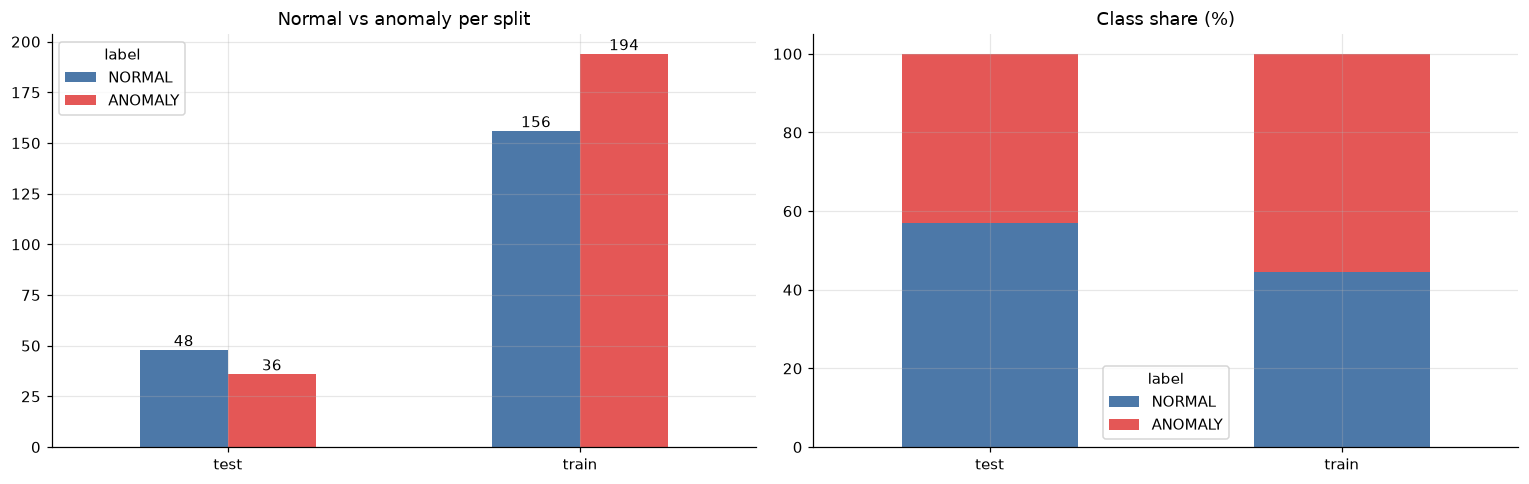

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ct = pd.crosstab(df.split, df.label)[["NORMAL", "ANOMALY"]]
ct.plot.bar(ax=axes[0], color=[C_NORM, C_ANOM], rot=0)
for c in axes[0].containers: axes[0].bar_label(c)
axes[0].set_title("Normal vs anomaly per split"); axes[0].set_xlabel("")
(ct.T / ct.sum(1)).T.mul(100).round(1).plot.bar(ax=axes[1], color=[C_NORM, C_ANOM], rot=0, stacked=True)
axes[1].set_title("Class share (%)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/class_balance.png"); plt.show()

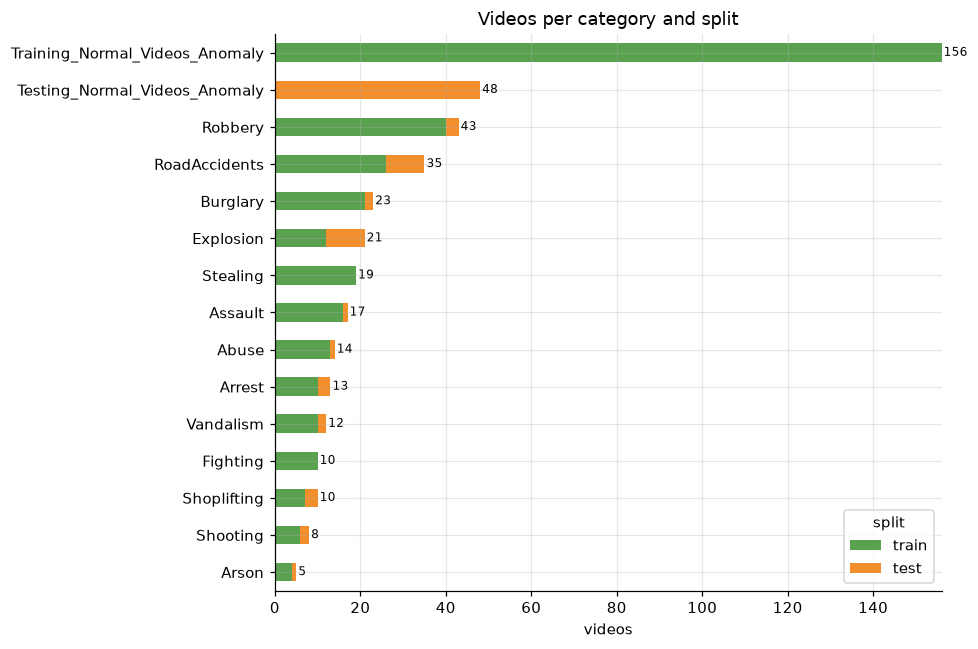

split,test,train,total
category,,,
Training_Normal_Videos_Anomaly,0,156,156
Testing_Normal_Videos_Anomaly,48,0,48
Robbery,3,40,43
RoadAccidents,9,26,35
Burglary,2,21,23
Explosion,9,12,21
Stealing,0,19,19
Assault,1,16,17
Abuse,1,13,14


In [4]:
cat = pd.crosstab(df.category, df.split)
cat["total"] = cat.sum(1); cat = cat.sort_values("total")
ax = cat[["train", "test"]].plot.barh(stacked=True, figsize=(9, 6), color=["#59A14F", "#F28E2B"])
ax.set_title("Videos per category and split"); ax.set_xlabel("videos"); ax.set_ylabel("")
for i, t in enumerate(cat.total): ax.text(t + .5, i, int(t), va="center", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/category_counts.png"); plt.show()
cat.sort_values("total", ascending=False)

## 2. Files on disk vs. files in the splits

In [5]:
on_disk = pd.DataFrame({"path": sorted(glob.glob(f"{VIDEOS_DIR}/*/*.mp4"))})
on_disk["category"] = on_disk.path.map(lambda p: os.path.basename(os.path.dirname(p)))
on_disk["in_split"] = on_disk.path.isin(set(df.path))
print("mp4 on disk:", len(on_disk), "| listed in a split:", on_disk.in_split.sum(), "| not in any split:", (~on_disk.in_split).sum())
print("\nunused files per folder:"); print(on_disk[~on_disk.in_split].category.value_counts().to_string())
print("\nNote: the split files only list the videos in train/test; the label is derived from the folder name ('Normal' in folder => NORMAL).")

mp4 on disk: 445 | listed in a split: 434 | not in any split: 11

unused files per folder:
category
z_Normal_Videos_event    11

Note: the split files only list the videos in train/test; the label is derived from the folder name ('Normal' in folder => NORMAL).


## 3. Video metadata and corrupt-file check
Only headers are read (fast); a frame is also decoded to confirm the file opens.

In [6]:
def probe(path):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        return dict(path=path, ok=False)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); fps = cap.get(cv2.CAP_PROP_FPS)
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fourcc = "".join(chr((int(cap.get(cv2.CAP_PROP_FOURCC)) >> 8 * i) & 255) for i in range(4))
    ok, _ = cap.read(); cap.release()
    return dict(path=path, ok=ok, frames=n, fps=fps, width=w, height=h, codec=fourcc,
                duration_s=n / fps if fps else np.nan, size_mb=os.path.getsize(path) / 1e6)

with ThreadPoolExecutor(16) as ex:
    meta = pd.DataFrame(list(tqdm(ex.map(probe, on_disk.path), total=len(on_disk))))
meta = on_disk.merge(meta, on="path").merge(df[["path", "split", "label"]], on="path", how="left")
meta["label"] = meta.label.fillna(meta.category.map(lambda c: "NORMAL" if "Normal" in c else "ANOMALY"))
meta["split"] = meta.split.fillna("unused")
meta["clips"] = np.ceil(meta.frames / CLIP_LEN)
print("unreadable files:", (~meta.ok.astype(bool)).sum())
meta[meta.ok == False][["path"]] if (~meta.ok.astype(bool)).any() else print("all videos open and decode")

  0%|          | 0/445 [00:00<?, ?it/s]

  7%|▋         | 31/445 [00:00<00:01, 293.09it/s]

 22%|██▏       | 98/445 [00:00<00:00, 431.61it/s]

 38%|███▊      | 171/445 [00:00<00:00, 531.32it/s]

 53%|█████▎    | 238/445 [00:00<00:00, 559.07it/s]

 66%|██████▌   | 294/445 [00:00<00:00, 539.42it/s]

 78%|███████▊  | 348/445 [00:00<00:00, 431.25it/s]

 89%|████████▊ | 394/445 [00:00<00:00, 418.34it/s]

100%|██████████| 445/445 [00:00<00:00, 463.39it/s]

unreadable files: 0
all videos open and decode


In [7]:
used = meta[meta.split != "unused"]
print("Used videos:", len(used))
summ = (used.width.astype(int).astype(str) + "x" + used.height.astype(int).astype(str)).value_counts()
print("\nResolutions:"); print(summ.to_string())
print("\nFPS:"); print(used.fps.round(2).value_counts().to_string())
print("\nCodec:"); print(used.codec.value_counts().to_string())
used[["frames", "duration_s", "size_mb", "clips"]].describe().round(2)

Used videos: 434

Resolutions:
320x240    434

FPS:
fps
30.0    432
25.0      2

Codec:
codec
h264    434


,frames,duration_s,size_mb,clips
count,434.00,434.00,434.00,434.00
mean,7317.34,243.96,55.50,457.81
std,32992.28,1099.73,282.14,2062.03
min,203.00,6.77,0.85,13.00
25%,1124.00,37.47,7.23,71.00
50%,2137.50,71.92,14.39,134.00
75%,4547.00,151.57,32.36,284.50
max,628020.00,20934.00,5476.07,39252.00


## 4. Duration and clip counts
In notebook 03 each video is a bag of non-overlapping 16-frame clips, so `clips` is the bag size.

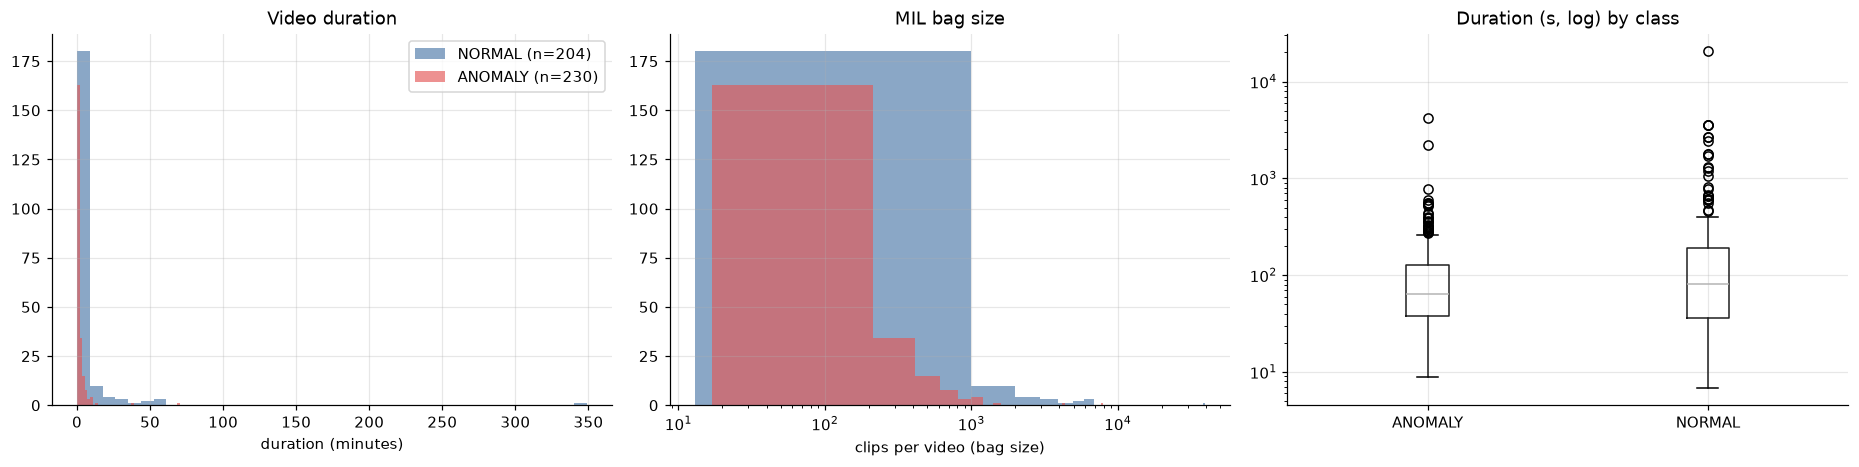

label               ANOMALY    NORMAL
duration_s mean       137.7     363.7
           median      64.6      80.2
           min          8.8       6.8
           max       4218.4   20934.0
frames     mean      4131.5   10909.3
           median    1937.0    2379.5
           min        263.0     203.0
           max     126553.0  628020.0
clips      mean       258.7     682.3
           median     121.5     149.5
           min         17.0      13.0
           max       7910.0   39252.0
size_mb    mean        29.3      85.1
           median      13.1      15.8
           min          1.1       0.9
           max        992.1    5476.1

Total hours: 29.4 | total frames: 3175726 | total clips: 198689


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for lab, col in [("NORMAL", C_NORM), ("ANOMALY", C_ANOM)]:
    d = used[used.label == lab]
    axes[0].hist(d.duration_s / 60, bins=40, alpha=.65, color=col, label=f"{lab} (n={len(d)})")
    axes[1].hist(d.clips, bins=40, alpha=.65, color=col, label=lab)
axes[0].set_xlabel("duration (minutes)"); axes[0].set_title("Video duration"); axes[0].legend()
axes[1].set_xlabel("clips per video (bag size)"); axes[1].set_title("MIL bag size"); axes[1].set_xscale("log")
used.boxplot(column="duration_s", by="label", ax=axes[2], grid=True); axes[2].set_yscale("log")
axes[2].set_title("Duration (s, log) by class"); plt.suptitle(""); axes[2].set_xlabel("")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/duration.png"); plt.show()
print(used.groupby("label")[["duration_s", "frames", "clips", "size_mb"]].agg(["mean", "median", "min", "max"]).round(1).T.to_string())
print("\nTotal hours:", round(used.duration_s.sum() / 3600, 1), "| total frames:", int(used.frames.sum()), "| total clips:", int(used.clips.sum()))

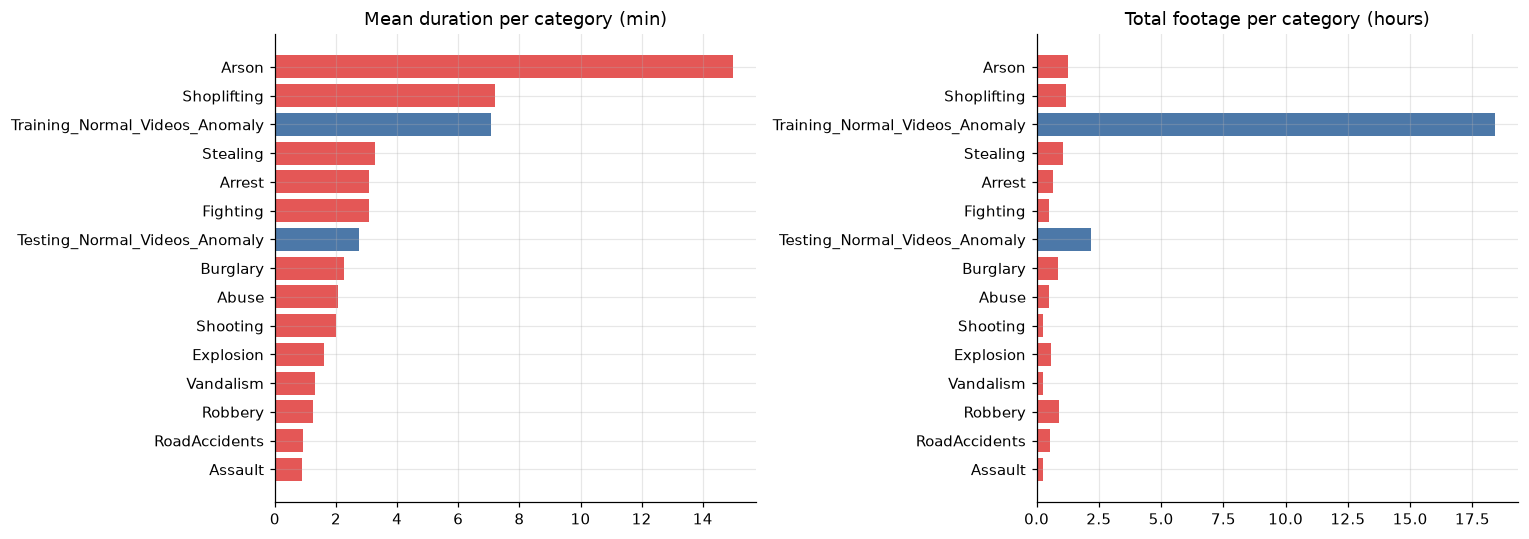

,videos,mean_min,median_clips,total_hours
category,,,,
Arson,5,15.00,152.0,1.25
Shoplifting,10,7.20,372.5,1.20
Training_Normal_Videos_Anomaly,156,7.08,170.5,18.41
Stealing,19,3.29,297.0,1.04
Arrest,13,3.09,184.0,0.67
Fighting,10,3.08,257.5,0.51
Testing_Normal_Videos_Anomaly,48,2.75,91.0,2.20
Burglary,23,2.26,161.0,0.87
Abuse,14,2.05,151.0,0.48


In [9]:
g = used.groupby("category").agg(videos=("path", "size"), mean_min=("duration_s", lambda s: s.mean() / 60),
                                  median_clips=("clips", "median"), total_hours=("duration_s", lambda s: s.sum() / 3600)).round(2)
g = g.sort_values("mean_min")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(g.index, g.mean_min, color=["#4C78A8" if "Normal" in i else "#E45756" for i in g.index]); axes[0].set_title("Mean duration per category (min)")
axes[1].barh(g.index, g.total_hours, color=["#4C78A8" if "Normal" in i else "#E45756" for i in g.index]); axes[1].set_title("Total footage per category (hours)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/duration_per_category.png"); plt.show()
g.sort_values("mean_min", ascending=False)

In [10]:
ratio = used.groupby("label").duration_s.sum()
print("Footage share (%):", (ratio / ratio.sum() * 100).round(1).to_dict(), "| video-count share (%):", (used.label.value_counts(normalize=True) * 100).round(1).to_dict())
top = used.nlargest(8, "duration_s").copy(); top["video"] = top.path.str.replace(VIDEOS_DIR + "/", "", regex=False)
print("\nLongest 8 videos:"); print(top[["video", "duration_s", "clips"]].round(0).to_string(index=False))

Footage share (%): {'ANOMALY': 29.9, 'NORMAL': 70.1} | video-count share (%): {'ANOMALY': 53.0, 'NORMAL': 47.0}

Longest 8 videos:
                                                   video  duration_s   clips
Training_Normal_Videos_Anomaly/Normal_Videos307_x264.mp4     20934.0 39252.0
                                 Arson/Arson019_x264.mp4      4218.0  7910.0
Testing_Normal_Videos_Anomaly/Normal_Videos_935_x264.mp4      3600.0  6750.0
Training_Normal_Videos_Anomaly/Normal_Videos666_x264.mp4      3599.0  6749.0
Training_Normal_Videos_Anomaly/Normal_Videos331_x264.mp4      3596.0  6744.0
Training_Normal_Videos_Anomaly/Normal_Videos785_x264.mp4      2700.0  5062.0
Training_Normal_Videos_Anomaly/Normal_Videos396_x264.mp4      2662.0  4991.0
Training_Normal_Videos_Anomaly/Normal_Videos713_x264.mp4      2434.0  4565.0


## 5. Image statistics — normal vs anomaly
12 frames evenly spaced per video: brightness, contrast, sharpness (variance of Laplacian), and motion (mean abs. difference between consecutive sampled frames). These are cheap cues a model could exploit by accident, so it matters if the classes differ.

In [11]:
N_FR = 12
def frame_stats(path):
    cap = cv2.VideoCapture(path); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    idx = np.linspace(0, max(n - 2, 0), N_FR).astype(int); prev = None; b, c, s, m = [], [], [], []
    for i in idx:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, f = cap.read()
        if not ok: continue
        g = cv2.cvtColor(cv2.resize(f, (320, 240)), cv2.COLOR_BGR2GRAY).astype(np.float32)
        b.append(g.mean()); c.append(g.std()); s.append(cv2.Laplacian(g, cv2.CV_32F).var())
        if prev is not None: m.append(np.abs(g - prev).mean())
        prev = g
    cap.release()
    return dict(path=path, brightness=np.mean(b), contrast=np.mean(c), sharpness=np.mean(s), motion=np.mean(m) if m else np.nan,
                dark_frac=np.mean(np.array(b) < 40))

with ThreadPoolExecutor(16) as ex:
    st = pd.DataFrame(list(tqdm(ex.map(frame_stats, used.path), total=len(used))))
used = used.merge(st, on="path")
used.groupby("label")[["brightness", "contrast", "sharpness", "motion", "dark_frac"]].agg(["mean", "std"]).round(2).T

  0%|          | 0/434 [00:00<?, ?it/s]

  0%|          | 1/434 [00:00<02:18,  3.12it/s]

  1%|          | 3/434 [00:00<01:11,  6.00it/s]

  4%|▍         | 17/434 [00:00<00:11, 37.61it/s]

  6%|▌         | 24/434 [00:00<00:10, 38.64it/s]

  7%|▋         | 30/434 [00:01<00:12, 32.14it/s]

... (53 outputs left out)

 96%|█████████▌| 417/434 [00:11<00:00, 31.29it/s]

 99%|█████████▉| 431/434 [00:11<00:00, 51.51it/s]

100%|██████████| 434/434 [00:11<00:00, 37.43it/s]

label                ANOMALY       NORMAL
brightness mean    89.470001    89.339996
           std     28.290001    21.879999
contrast   mean    62.290001    65.029999
           std     13.090000    11.350000
sharpness  mean  1559.920044  2454.149902
           std   1242.500000  1486.050049
motion     mean    15.750000    16.240000
           std     11.390000    16.450001
dark_frac  mean     0.050000     0.030000
           std      0.160000     0.100000

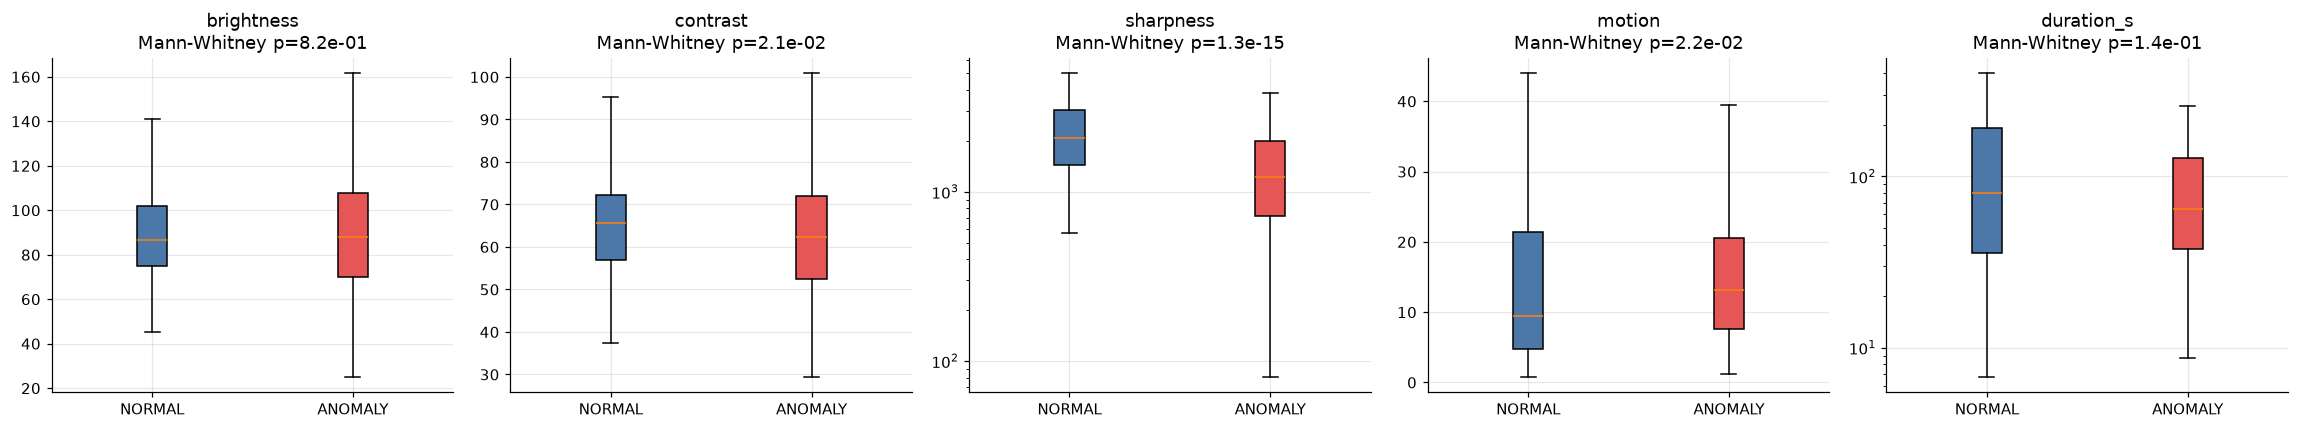

,feature,median NORMAL,median ANOMALY,p-value
0,brightness,86.5952,88.2014,0.8225
1,contrast,65.5449,62.3340,0.0213
2,sharpness,2064.9531,1218.3291,0.0000
3,motion,9.4499,13.1892,0.0221
4,duration_s,80.2167,64.5667,0.1370


In [12]:
from scipy.stats import mannwhitneyu
feats = ["brightness", "contrast", "sharpness", "motion", "duration_s"]
fig, axes = plt.subplots(1, 5, figsize=(21, 4))
rows = []
for ax, f in zip(axes, feats):
    a, n = used[used.label == "ANOMALY"][f].dropna(), used[used.label == "NORMAL"][f].dropna()
    bp = ax.boxplot([n, a], tick_labels=["NORMAL", "ANOMALY"], patch_artist=True, showfliers=False)
    for p, col in zip(bp["boxes"], [C_NORM, C_ANOM]): p.set_facecolor(col)
    if f in ("sharpness", "duration_s"): ax.set_yscale("log")
    pv = mannwhitneyu(a, n).pvalue; ax.set_title(f"{f}\nMann-Whitney p={pv:.1e}")
    rows.append((f, n.median(), a.median(), pv))
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/image_stats.png"); plt.show()
pd.DataFrame(rows, columns=["feature", "median NORMAL", "median ANOMALY", "p-value"]).round(4)

In [13]:
# How well do these dataset-level cues alone separate the classes? (AUC of each feature, and a tiny classifier)
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
y = (used.label == "ANOMALY").astype(int).values
print("Single-feature ROC-AUC (0.5 = no signal):")
for f in feats + ["dark_frac"]:
    v = used[f].fillna(used[f].median()).values; print(f"  {f:12s} {max(roc_auc_score(y, v), 1 - roc_auc_score(y, v)):.3f}")
X = np.log1p(used[feats + ["dark_frac"]].fillna(0).clip(lower=0).values)
auc = cross_val_score(LogisticRegression(max_iter=2000, class_weight="balanced"), (X - X.mean(0)) / X.std(0), y,
                      cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
print(f"\nLogistic regression on these 6 trivial features, 5-fold ROC-AUC: {auc.mean():.3f} ± {auc.std():.3f}")
print("Compare with the CLIP+MIL CV ROC-AUC of 0.9585; if this number is close, part of the task is solvable by non-semantic cues.")

Single-feature ROC-AUC (0.5 = no signal):
  brightness   0.506
  contrast     0.564
  sharpness    0.722
  motion       0.564
  duration_s   0.541
  dark_frac    0.541

Logistic regression on these 6 trivial features, 5-fold ROC-AUC: 0.721 ± 0.052
Compare with the CLIP+MIL CV ROC-AUC of 0.9585; if this number is close, part of the task is solvable by non-semantic cues.


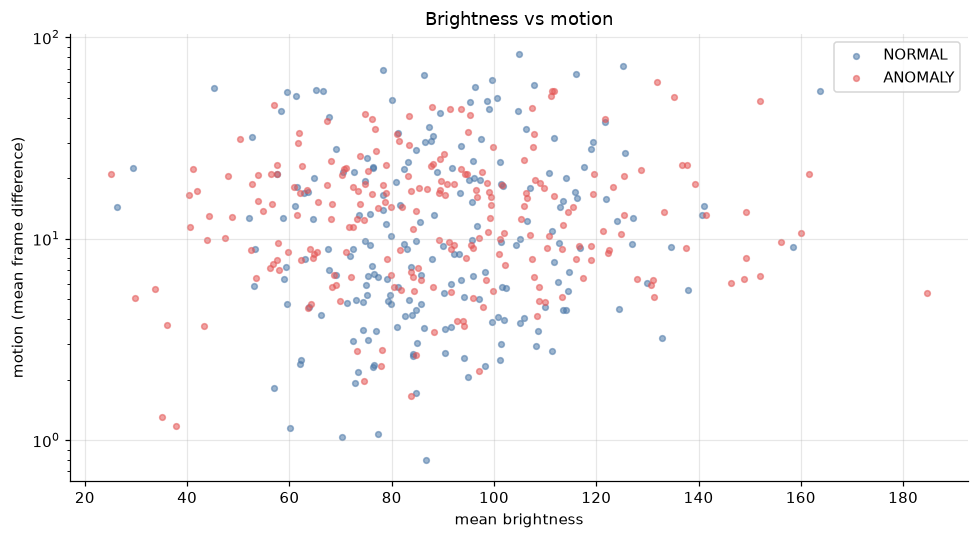

,brightness,contrast,motion,dark_frac
category,,,,
Fighting,87.730003,60.320000,22.570000,0.02
Arrest,77.650002,63.529999,19.879999,0.06
Arson,68.410004,58.310001,19.320000,0.08
Abuse,98.129997,59.840000,19.120001,0.05
Assault,89.949997,63.779999,18.799999,0.04
Explosion,90.690002,65.239998,18.600000,0.04
Training_Normal_Videos_Anomaly,88.510002,64.870003,18.049999,0.04
Shooting,80.370003,63.490002,17.930000,0.03
Shoplifting,92.470001,63.020000,17.520000,0.02


In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
for lab, col in [("NORMAL", C_NORM), ("ANOMALY", C_ANOM)]:
    d = used[used.label == lab]; ax.scatter(d.brightness, d.motion, s=14, alpha=.55, color=col, label=lab)
ax.set_xlabel("mean brightness"); ax.set_ylabel("motion (mean frame difference)"); ax.set_yscale("log"); ax.legend(); ax.set_title("Brightness vs motion")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/brightness_motion.png"); plt.show()
used.groupby("category")[["brightness", "contrast", "motion", "dark_frac"]].mean().round(2).sort_values("motion", ascending=False)

## 6. Sample frames per category
One frame from the middle of a random video of each category.

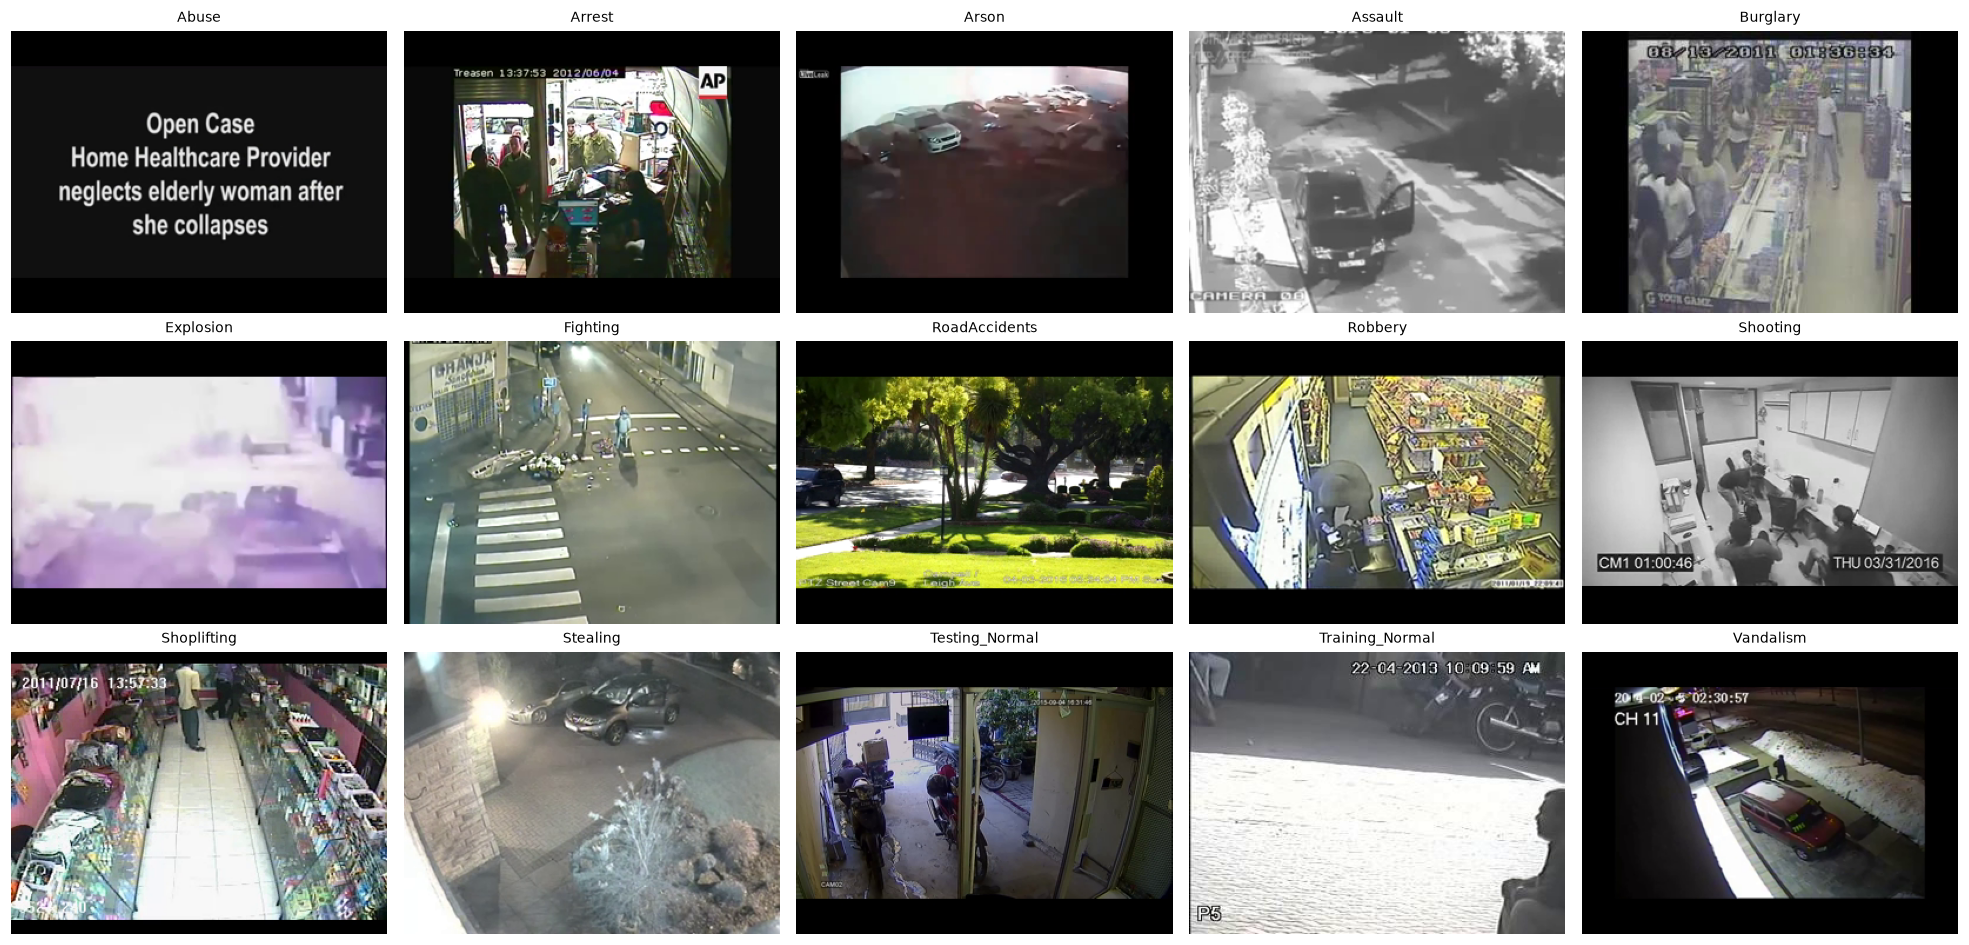

In [15]:
rng = np.random.RandomState(0)
cats = sorted(used.category.unique()); cols = 5; rows_ = int(np.ceil(len(cats) / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(3.6 * cols, 2.9 * rows_))
for ax in axes.ravel(): ax.axis("off")
for ax, c in zip(axes.ravel(), cats):
    p = rng.choice(used[used.category == c].path); cap = cv2.VideoCapture(p)
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT) // 2)); ok, f = cap.read(); cap.release()
    if ok: ax.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    ax.set_title(c.replace("_Videos_Anomaly", ""), fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/samples.png"); plt.show()

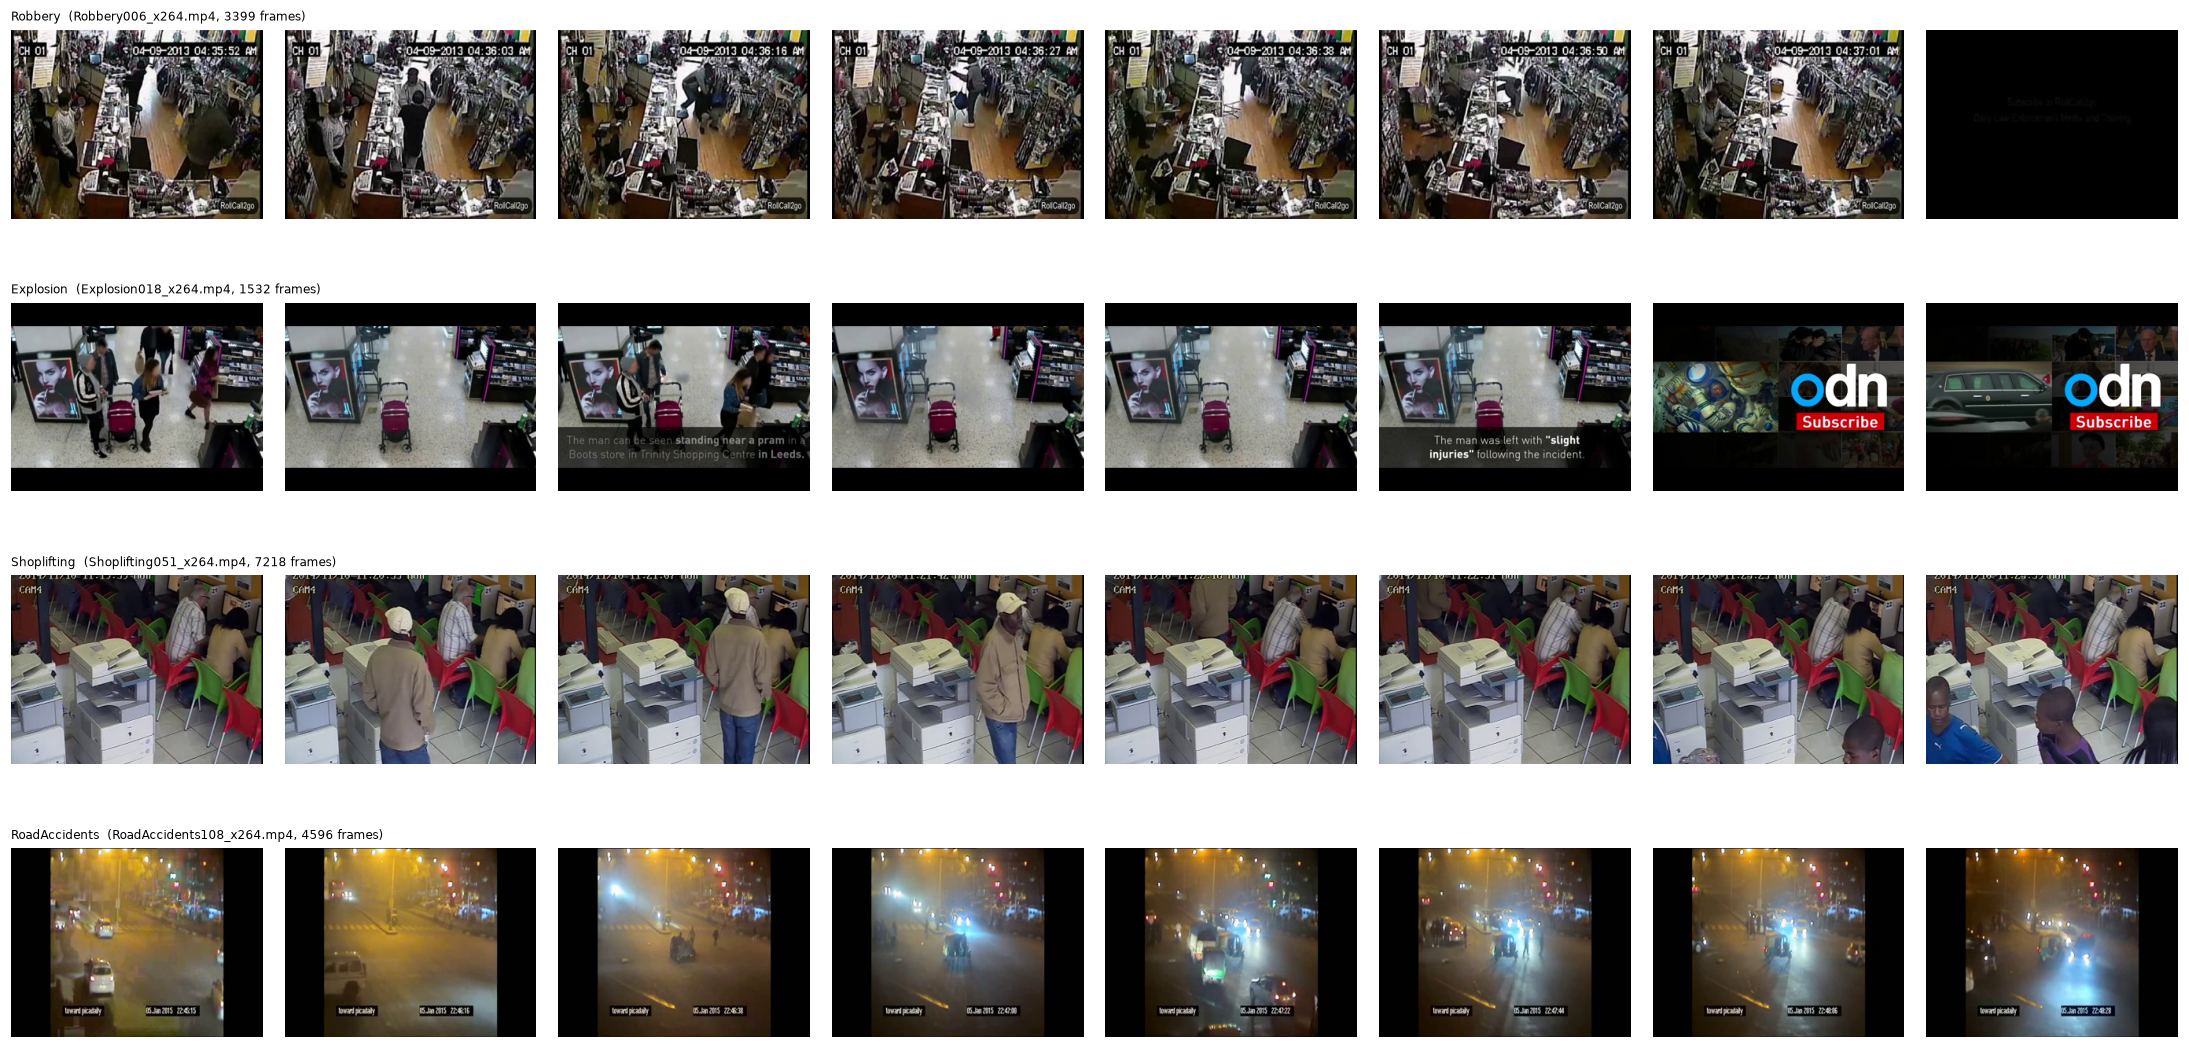

In [16]:
# A temporal strip (8 frames across the video) for one video of a few anomaly categories
show = ["Robbery", "Explosion", "Shoplifting", "RoadAccidents"]
fig, axes = plt.subplots(len(show), 8, figsize=(20, 2.6 * len(show)))
for r, c in enumerate(show):
    p = rng.choice(used[used.category == c].path); cap = cv2.VideoCapture(p); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    for k, i in enumerate(np.linspace(0, n - 2, 8).astype(int)):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, f = cap.read(); axes[r, k].axis("off")
        if ok: axes[r, k].imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        if k == 0: axes[r, k].set_title(f"{c}  ({os.path.basename(p)}, {n} frames)", fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/temporal_strips.png"); plt.show()

## 7. Duplicates and findings

In [17]:
def head_hash(p, n=1 << 20):
    with open(p, "rb") as f: return hashlib.md5(f.read(n)).hexdigest()
used["hash"] = [head_hash(p) for p in used.path]
dup = used[used.duplicated("hash", keep=False)].sort_values("hash")
print("videos sharing an identical first-1MB hash:", len(dup))
size_dup = used[used.duplicated(["size_mb", "frames"], keep=False)]
print("videos sharing identical size and frame count:", len(size_dup))
if len(dup): print(dup[["path", "split"]].assign(path=dup.path.str.replace(VIDEOS_DIR + "/", "")).to_string(index=False))
tr, te = set(used[used.split == "train"].hash), set(used[used.split == "test"].hash)
print("train/test videos with identical content hash:", len(tr & te))

videos sharing an identical first-1MB hash: 0
videos sharing identical size and frame count: 0
train/test videos with identical content hash: 0


In [18]:
n_tr, n_te = (used.split == "train").sum(), (used.split == "test").sum()
tr = used[used.split == "train"]; te = used[used.split == "test"]
small = cat[(cat.train > 0) & (cat.train < 15)].index.tolist()
print(f"""
SUMMARY
- {len(used)} videos used ({n_tr} train / {n_te} test), {used.duration_s.sum()/3600:.1f} h of footage, {int(used.clips.sum()):,} 16-frame clips.
- Train: {(tr.label=='ANOMALY').mean()*100:.0f}% anomaly / {(tr.label=='NORMAL').mean()*100:.0f}% normal. Test: {(te.label=='ANOMALY').mean()*100:.0f}% anomaly / {(te.label=='NORMAL').mean()*100:.0f}% normal.
- Categories with fewer than 15 training videos (per-category accuracy is noisy for these): {small}
- Median duration: normal {used[used.label=='NORMAL'].duration_s.median():.0f}s vs anomaly {used[used.label=='ANOMALY'].duration_s.median():.0f}s.
- Mean bag size: {used.clips.mean():.0f} clips (min {int(used.clips.min())}, max {int(used.clips.max())}).
- Unreadable videos: {(~used.ok.astype(bool)).sum()}.
""")
used.drop(columns=["ok"]).to_csv(f"{OUT_DIR}/video_metadata.csv", index=False)
print("saved", f"{OUT_DIR}/video_metadata.csv")


SUMMARY
- 434 videos used (350 train / 84 test), 29.4 h of footage, 198,689 16-frame clips.
- Train: 55% anomaly / 45% normal. Test: 43% anomaly / 57% normal.
- Categories with fewer than 15 training videos (per-category accuracy is noisy for these): ['Arson', 'Shooting', 'Shoplifting', 'Fighting', 'Vandalism', 'Arrest', 'Abuse', 'Explosion']
- Median duration: normal 80s vs anomaly 65s.
- Mean bag size: 458 clips (min 13, max 39252).
- Unreadable videos: 0.

saved ./runs_eda/video_metadata.csv
